# Course: M4010104 / M4020104 — Programming in Python
## Module 3 · Week 9: Numerical Computing with NumPy
### 1D & 2D Arrays, Indexing, Slicing, Reshaping, Vectorization & Statistical Tools
### Interactive Lecture Slides cum Laboratory Practical Workbook
**Digital University Kerala (DUK) · International Centre for Free and Open Source Solutions (ICFOSS)**

---

### Student Identification & Academic Record
*Please complete all entries in this block before beginning your session.*

```
========================================================================================
  STUDENT NAME            : ____________________________________________________________
  ROLL NUMBER / ID        : ____________________________________________________________
  PROGRAMME / BATCH       : [ ] MTech AI    [ ] MSc AI
  DATE OF SESSION         : ____________________________________________________________
  LAB PARTNER NAME        : ____________________________________________________________
  ASSIGNED WORKSTATION NO : ____________________________________________________________
  CAPSTONE TEAM ID / NO   : ____________________________________________________________
  ASSIGNMENT 3 STATUS     : [ ] Assignment 3 Released (Due in Week 10)
  EVALUATION MARKS AWARDED: _______ / 25 Marks  (TA / Faculty Evaluation)
========================================================================================
```

---

### Instructional Guide
- **Interactive Lecture Component**: Follow along with **Dr. Sunil TT**. Execute each demonstration cell, examine line-by-line comments, study the visual memory/array diagrams, and complete the **In-Class Quick-Checks** after each topic.
  - **Part 1** — Why NumPy? The `ndarray` Architecture, Creation Routines & Memory Types (`dtype`)
  - **Part 2** — 1D & 2D Indexing, Slicing & The Crucial "View vs. Copy" Trap
  - **Part 3** — Reshaping, Flattening (`ravel` vs `flatten`) & Matrix Transposition
  - **Part 4** — Vectorized Arithmetic, Broadcasting Mechanics & Loop Performance
  - **Part 5** — Statistical & Reduction Tools (`mean`, `median`, `std`, `var`, `axis=0` vs `axis=1`)
- **Laboratory Practical Component**: Proceed to **Part 6: Laboratory Practical Workbook**.
  - **Tier 1 (Core Problems C1–C6)**: Mandatory for all students (15 Marks) — Array creation, reshaping, slicing views, boolean masking, axis-wise stats, and loop-vs-vectorization benchmarking.
  - **Tier 2 (Advanced Problems A1–A4)**: Optional bonus challenges (10 Marks) — 2D Moving Window Convolution, Feature Standardization, Broadcasting Distance Matrix, and Assignment 3 Data Primer.

---
## Week 9 Syllabus & Learning Outcomes (Mapped to CO3)

### Course Plan Alignment:
- **Module 3**: Perform advanced programming using NumPy and Pandas by creating, manipulating and aggregating arrays and data frames to extract meaningful insights from structured data.
- **Lecture Topics**: Introduction to NumPy: 1D and 2D arrays; looping over arrays; statistical tools.
- **Laboratory Topics**: Array creation, reshaping and slicing; computing mean, median and standard deviation.

### Learning Outcomes:
By the end of this session, you will be able to:
1. **Explain the Architecture of `ndarray`**: Differentiate NumPy's contiguous, homogeneous memory layout from standard Python lists.
2. **Utilize Array Creation Routines**: Create arrays using `np.array()`, `np.zeros()`, `np.ones()`, `np.full()`, `np.arange()`, `np.linspace()`, and `np.eye()`.
3. **Master Multi-Dimensional Slicing**: Extract sub-matrices, manipulate strides, and avoid accidental data corruption caused by array views.
4. **Reshape & Transform Arrays**: Reorganize dimensions using `.reshape()`, `.ravel()`, `.flatten()`, and transposition (`.T`).
5. **Leverage Vectorization & Broadcasting**: Replace nested loops with instantaneous SIMD vectorized arithmetic and understand broadcasting dimension expansion.
6. **Apply Axis-Wise Statistical Reductions**: Compute `mean()`, `median()`, `std()`, `var()`, `sum()`, and `argmax()` along specific dimensions (`axis=0` vs `axis=1`).


---
# Part 1: Why NumPy? The `ndarray` Architecture & Creation Routines
In scientific computing, machine learning, and artificial intelligence, processing millions of numbers with standard Python lists is prohibitively slow and memory-inefficient.

```
       Standard Python List: [10, 20, 30]                NumPy ndarray: np.array([10, 20, 30])
+-------------------------------------------------+     +-----------------------------------------+
| List of Pointers to Separate Heap Objects       |     | Contiguous Block of Uniform C Primitives |
|                                                 |     |                                         |
|  [ ptr_0 ] ------> (PyObject: int 10, 28 bytes) |     |  +------------+------------+------------+
|  [ ptr_1 ] ------> (PyObject: int 20, 28 bytes) |     |  | int32 (10) | int32 (20) | int32 (30) |
|  [ ptr_2 ] ------> (PyObject: int 30, 28 bytes) |     |  +------------+------------+------------+
|  High memory overhead, non-contiguous cache     |     |  Continuous memory, SIMD vectorization! |
+-------------------------------------------------+     +-----------------------------------------+
```

### Why NumPy Dominates AI & Data Science:
1. **Contiguous Memory**: Values sit directly adjacent in RAM, maximizing CPU L1/L2 cache hits.
2. **Homogeneous Data Types (`dtype`)**: All elements have the exact same binary size (e.g. `int32`, `float64`), eliminating per-element type-checking overhead during loops.
3. **Vectorized SIMD Operations**: Instructions execute directly in compiled C/Fortran routines across entire arrays simultaneously without Python interpreter overhead.


### What is NumPy?

**NumPy** (short for *Numerical Python*) is the foundational library for scientific computing and data analysis in Python. It provides the core mathematical backbone for almost all high-performance AI, machine learning, and deep learning libraries, including Pandas, Scikit-Learn, TensorFlow, and PyTorch.

#### Key Features of NumPy:
1. **The `ndarray` Object**: At its heart is the `ndarray` (N-dimensional array), a fast, flexible, and memory-efficient multi-dimensional array container.
2. **Homogeneous Data**: Unlike standard Python lists which can store mixed data types, all elements in a NumPy array must be of the **same data type** (homogeneous). This uniformity enables extremely fast, hardware-level performance.
3. **Vectorized Operations**: NumPy supports **vectorization**, allowing you to perform complex mathematical calculations on entire arrays instantly without writing slow Python `for` loops.
4. **Broadcasting**: A powerful mechanism that allows arithmetic operations between arrays of different shapes.
5. **Compiled C Backend**: NumPy's core computations are written in highly optimized C and Fortran, bypassing the typical performance overhead of the standard Python interpreter.

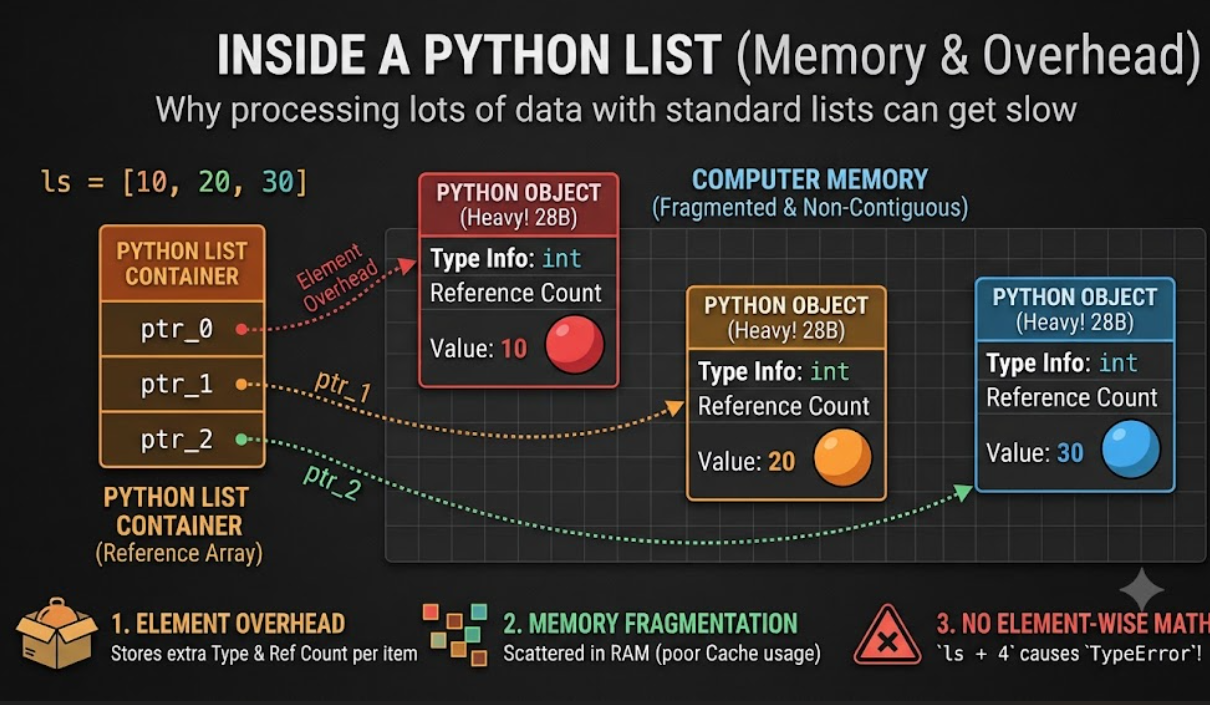

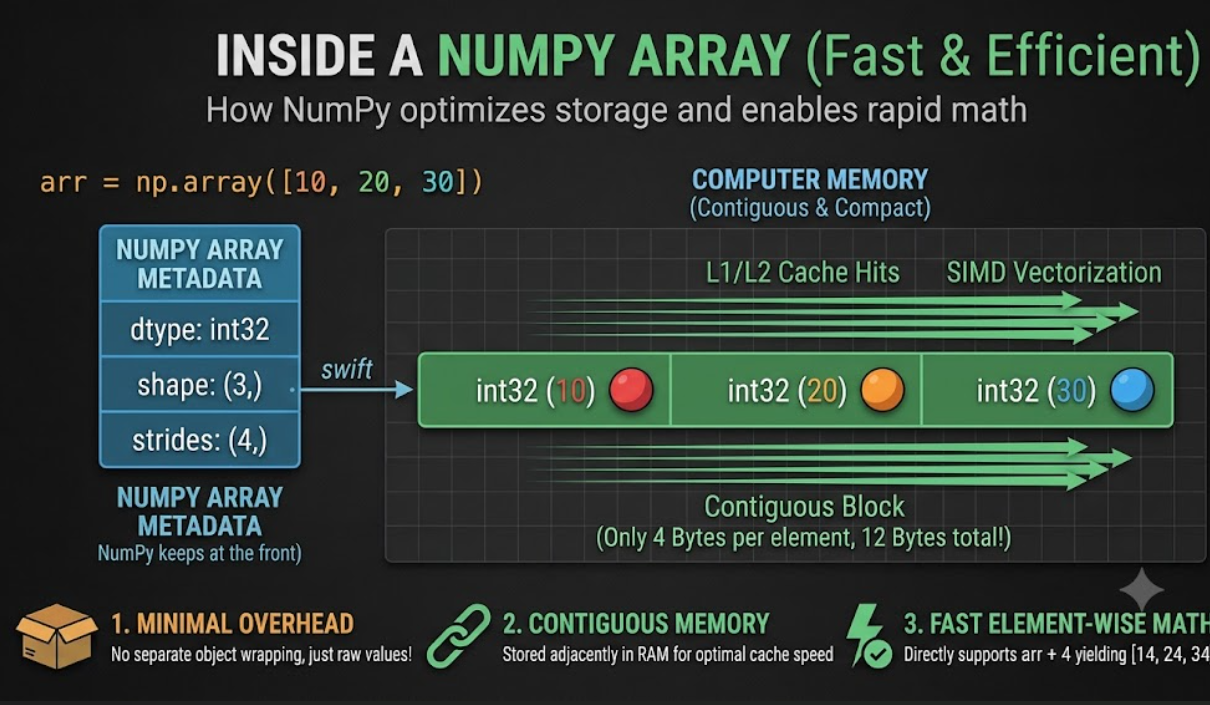

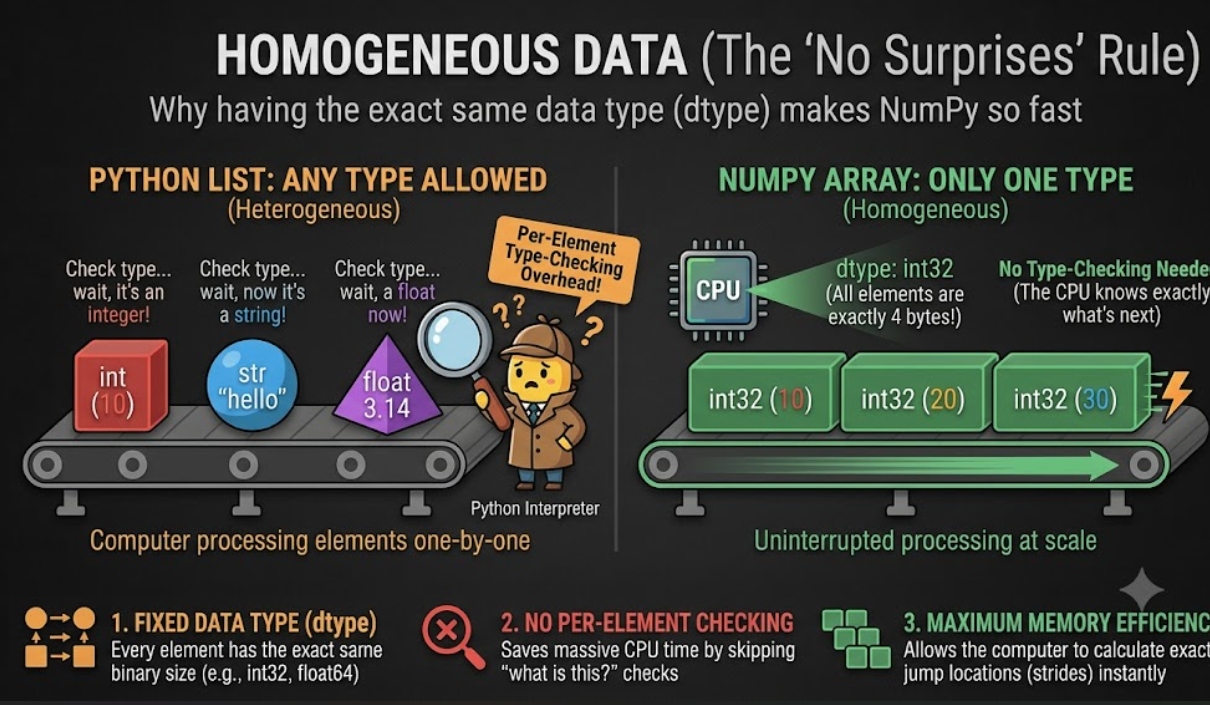

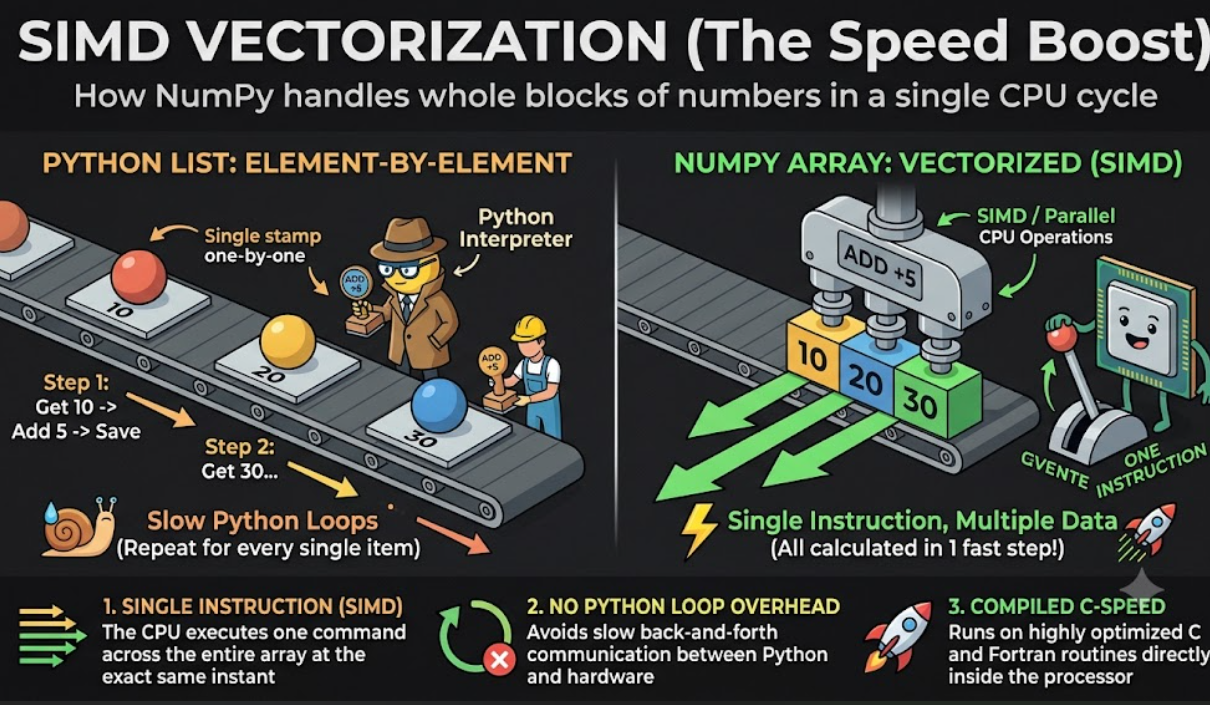

In [ ]:
# 1.1 Declaring and printing a NumPy array
import numpy as np

# Declare a simple 1D array (default integer type)
my_array = np.array([10, 20, 30, 40, 50])
print("1. Default Array:", my_array, "| dtype:", my_array.dtype)

# Example 1: Explicit 16-bit integer (saves memory)
arr_int16 = np.array([5, 10, 15], dtype=np.int16)
print("2. 16-bit Integer Array:", arr_int16, "| dtype:", arr_int16.dtype)

# Example 2: Explicit 32-bit float (standard for ML/Deep Learning)
arr_float32 = np.array([1.5, 2.7, 3.9], dtype=np.float32)
print("3. 32-bit Float Array:", arr_float32, "| dtype:", arr_float32.dtype)

# Example 3: Boolean array using explicit dtype
arr_bool = np.array([1, 0, 1], dtype=np.bool_)
print("4. Boolean Array:", arr_bool, "| dtype:", arr_bool.dtype)

1. Default Array: [10 20 30 40 50] | dtype: int64
2. 16-bit Integer Array: [ 5 10 15] | dtype: int16
3. 32-bit Float Array: [1.5 2.7 3.9] | dtype: float32
4. Boolean Array: [ True False  True] | dtype: bool


### NumPy Data Types (`dtype`) Reference Guide

Selecting the correct `dtype` is vital in AI and scientific computing to manage memory usage and optimize arithmetic execution speed. Below is a summary of the most common data types available in NumPy:

#### 1. Integers (Signed & Unsigned)
*   **`np.int8` / `np.uint8`** (1 byte): Range `-128` to `127` (or `0` to `255` for unsigned). Commonly used for pixel values in image processing.
*   **`np.int16` / `np.uint16`** (2 bytes): Range `-32,768` to `32,767` (or `0` to `65,535`). Ideal for digital audio signals.
*   **`np.int32` / `np.uint32`** (4 bytes): Standard precision integer. Often used for indexing and general integer arithmetic.
*   **`np.int64` / `np.uint64`** (8 bytes): High precision integer. Used when numbers exceed $\approx 2$ billion.

#### 2. Floating-Point Numbers
*   **`np.float16`** (2 bytes): Half precision. Popular in deep learning (e.g., mixed-precision training) to save GPU memory.
*   **`np.float32`** (4 bytes): Single precision. The **standard format** for weights and activations in deep learning models.
*   **`np.float64`** (8 bytes): Double precision. The default float type in NumPy, essential for high-accuracy scientific simulations.

#### 3. Other Core Types
*   **`np.bool_`** (1 byte): Stores `True` or `False`. Used for boolean masks.
*   **`np.complex64` / `np.complex128`**: Used in signal processing and Fourier transforms to represent complex numbers ($a + bj$).

In [1]:
# 1.2 Creating 2D Matrices & Data Type Conversion (Plus 3D Array Examples)
import numpy as np

# =====================================================================
# EXAMPLE 1: Creating a 2D Matrix (3 rows x 4 columns)
# =====================================================================
matrix_2d = np.array([
    [1.5, 2.5, 3.5, 4.5],
    [5.0, 6.0, 7.0, 8.0],
    [9.5, 10.5, 11.5, 12.5]
], dtype=np.float64)

print("--- 2D Matrix ---")
print(matrix_2d)
print("Shape (Rows, Columns)   :", matrix_2d.shape)  # Returns (3, 4)
print("Number of Dimensions    :", matrix_2d.ndim)   # 2 dimensions (axes)
print("Total Elements (size)   :", matrix_2d.size)   # 3 * 4 = 12


# =====================================================================
# EXAMPLE 2: Creating a 3D Tensor / Multi-Dimensional Array
# Shape: (2 blocks, 3 rows, 4 columns) - commonly used in representing RGB images or time-series data
# =====================================================================
matrix_3d = np.array([
    [
        [1, 2, 3, 4],
        [5, 6, 7, 8],
        [9, 10, 11, 12]
    ],
    [
        [13, 14, 15, 16],
        [17, 18, 19, 20],
        [21, 22, 23, 24]
    ]
], dtype=np.int32)

print("\n--- 3D Array (Tensor) ---")
print(matrix_3d)
print("Shape (Blocks, Rows, Cols):", matrix_3d.shape) # Returns (2, 3, 4)
print("Number of Dimensions      :", matrix_3d.ndim)  # 3 dimensions
print("Total Elements (size)     :", matrix_3d.size)  # 2 * 3 * 4 = 24

--- 2D Matrix ---
[[ 1.5  2.5  3.5  4.5]
 [ 5.   6.   7.   8. ]
 [ 9.5 10.5 11.5 12.5]]
Shape (Rows, Columns)   : (3, 4)
Number of Dimensions    : 2
Total Elements (size)   : 12

--- 3D Array (Tensor) ---
[[[ 1  2  3  4]
  [ 5  6  7  8]
  [ 9 10 11 12]]

 [[13 14 15 16]
  [17 18 19 20]
  [21 22 23 24]]]
Shape (Blocks, Rows, Cols): (2, 3, 4)
Number of Dimensions      : 3
Total Elements (size)     : 24


In [ ]:
# 1.3 Built-in Array Generation Routines (The Essential Palette)
import numpy as np

# 1. np.zeros(shape): Array filled completely with 0.0
zeros_arr = np.zeros((2, 3))
print("np.zeros((2, 3)):\n", zeros_arr)

# 2. np.ones(shape): Array filled completely with 1.0
ones_arr = np.ones((2, 4), dtype=np.int16)
print("\nnp.ones((2, 4), int16):\n", ones_arr)

# 3. np.full(shape, fill_value): Array filled with a constant scalar
full_arr = np.full((3, 3), 7.5)
print("\nnp.full((3, 3), 7.5):\n", full_arr)

# 4. np.arange(start, stop, step): Integer or float range (Exclusive upper bound!)
arange_arr = np.arange(0, 20, 2)
print("\nnp.arange(0, 20, 2):", arange_arr)

# 5. np.linspace(start, stop, num_points): Linearly spaced points (INCLUSIVE upper bound!)
# Indispensable for calculus, trigonometry, plotting curves, and sampling sensors!
linspace_arr = np.linspace(0.0, 1.0, 5)
print("\nnp.linspace(0.0, 1.0, 5):", linspace_arr)

# 6. np.eye(N): Identity matrix of size N x N (1s on diagonal, 0s elsewhere)
identity_3x3 = np.eye(3)
print("\nnp.eye(3) Identity Matrix:\n", identity_3x3)

np.zeros((2, 3)):
 [[0. 0. 0.]
 [0. 0. 0.]]

np.ones((2, 4), int16):
 [[1 1 1 1]
 [1 1 1 1]]

np.full((3, 3), 7.5):
 [[7.5 7.5 7.5]
 [7.5 7.5 7.5]
 [7.5 7.5 7.5]]

np.arange(0, 20, 2): [ 0  2  4  6  8 10 12 14 16 18]

np.linspace(0.0, 1.0, 5): [0.   0.25 0.5  0.75 1.  ]

np.eye(3) Identity Matrix:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [ ]:
import numpy as np

# Set the random seed for reproducible results
np.random.seed(42)

# 1. Random floats in the interval [0.0, 1.0) of shape (3, 4)
rand_matrix = np.random.rand(3, 4)
print("1. Uniform Random Floats [0.0, 1.0):\n", rand_matrix)

# 2. Random integers in the range [10, 50) of shape (3, 3)
rand_ints = np.random.randint(10, 50, size=(3, 3))
print("\n2. Random Integers in [10, 50):\n", rand_ints)

# 3. Standard normal distribution (mean=0, std=1) of shape (2, 5)
normal_matrix = np.random.randn(2, 5)
print("\n3. Standard Normal Distribution Matrix:\n", normal_matrix)

### In-Class Quick Check 1: Array Creation
**Task**:
1. Create a 2D array of shape $(4, 5)$ filled entirely with the value `99.0` as `float32`.
2. Generate an array `t` of $11$ evenly spaced time points between $0.0$ and $2.0$ seconds using `np.linspace`.
3. Print both arrays and verify their shapes.


In [ ]:
# STUDENT ACTIVITY: Quick Check 1
# -------------------------------------------------------------
# TODO 1: Create a 4x5 array filled with 99.0 as np.float32
arr_99 =

# TODO 2: Create an array of 11 evenly spaced points between 0.0 and 2.0
t_points =

# ==========================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# ==========================================
# Your 'arr_99' should look like:
# [[99. 99. 99. 99. 99.]
#  [99. 99. 99. 99. 99.]
#  [99. 99. 99. 99. 99.]
#  [99. 99. 99. 99. 99.]]
#
# Your 't_points' should look like:
# [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2. ]

print("--- YOUR RESULTS ---")
print("4x5 Matrix of 99.0:\n", arr_99)
print("\nTime Points:", t_points)

# Auto-verification checks:
assert arr_99.shape == (4, 5), "Error: arr_99 must have a shape of (4, 5)"
assert len(t_points) == 11, "Error: t_points must have exactly 11 elements"
assert t_points[0] == 0.0 and t_points[-1] == 2.0, "Error: t_points must start at 0.0 and end at 2.0"
print("\n All checks passed successfully!")

--- YOUR RESULTS ---
4x5 Matrix of 99.0:
 [[99. 99. 99. 99. 99.]
 [99. 99. 99. 99. 99.]
 [99. 99. 99. 99. 99.]
 [99. 99. 99. 99. 99.]]

Time Points: [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2. ]

 All checks passed successfully!


---
# Part 2: 1D & 2D Indexing, Slicing & The "View vs. Copy" Trap
NumPy extends standard Python slicing into multidimensional arrays using clean comma-separated tuple indices: `array[row_slice, col_slice]`.

```
                    Column 0    Column 1    Column 2    Column 3
                  +-----------+-----------+-----------+-----------+
         Row 0    |    10     |    20     |    30     |    40     |
                  +-----------+-----------+-----------+-----------+
         Row 1    |    50     |    60     |    70     |    80     |
                  +-----------+-----------+-----------+-----------+
         Row 2    |    90     |    100    |    110    |    120    |
                  +-----------+-----------+-----------+-----------+

         Slicing syntax: arr[0:2, 1:3] extracts:
         Row 0 and 1, Columns 1 and 2 -> [[20, 30], [60, 70]]
```

### The Crucial "View vs. Copy" Trap:
- **Python List Slices**: Always return a brand new independent shallow copy: `b = my_list[:]`.
- **NumPy Array Slices**: Always return a **VIEW** of the original memory!
- **Consequence**: If you modify elements in a NumPy slice, **the original parent array is directly mutated!**
- To create an independent copy, you **must explicitly call `.copy()`**.

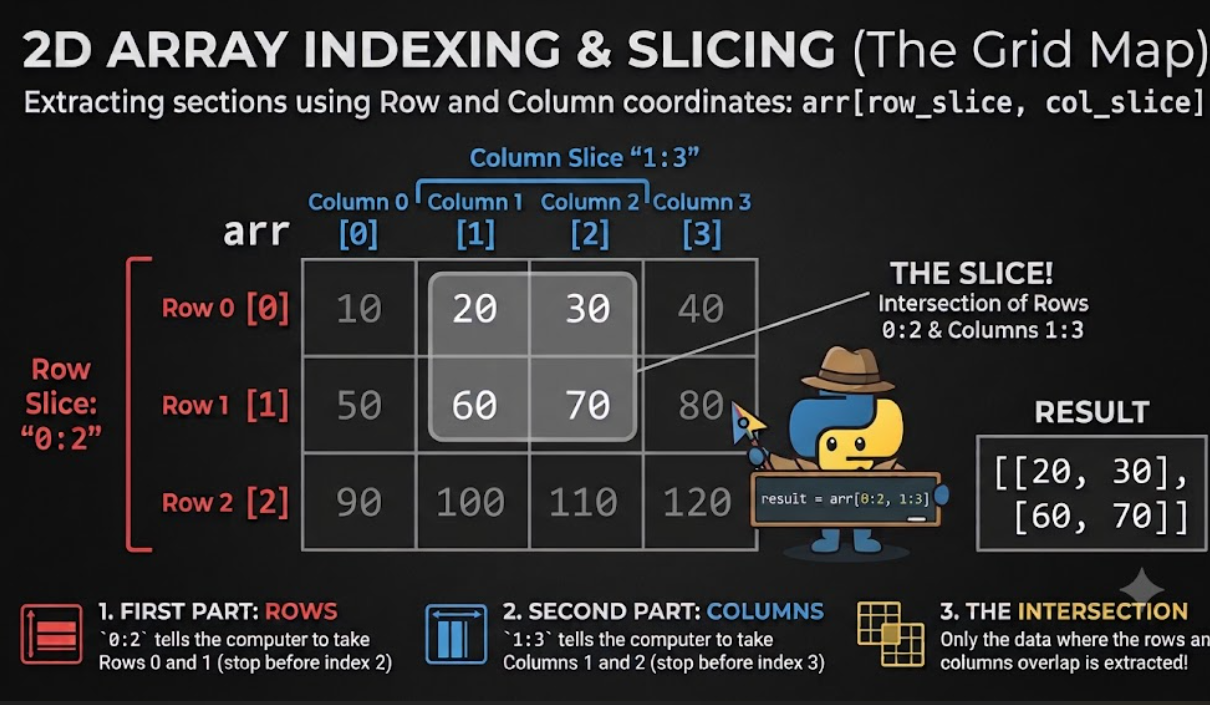

In [2]:
# 2.1 Multi-Dimensional Indexing and Slicing
import numpy as np

grid = np.array([
    [10, 20, 30, 40],
    [50, 60, 70, 80],
    [90, 100, 110, 120]
])

print("Original Grid (3x4):\n", grid)

# 1. Accessing a single scalar element: grid[row, col]
print("\nElement at Row 1, Col 2 (zero-based):", grid[1, 2])  # 70

# 2. Slicing an entire row or column using ':'
print("Row 0 (complete)    :", grid[0, :])     # [10, 20, 30, 40]
print("Column 3 (complete) :", grid[:, 3])     # [40, 80, 120]

# 3. Slicing a rectangular sub-matrix: rows 0..1, cols 1..2
sub_matrix = grid[0:2, 1:3]
print("\nSub-matrix grid[0:2, 1:3]:\n", sub_matrix)

# 4. Strided slicing: every 2nd row and every 2nd column
print("\nStrided grid[::2, ::2]:\n", grid[::2, ::2])

# =====================================================================
# ADDITIONAL EXAMPLES
# =====================================================================

# 5. Slicing with negative indices: Last row, last two elements
print("\nLast Row, Last 2 Elements (grid[-1, -2:]):", grid[-1, -2:])

# 6. Reversing the rows of the grid (using step of -1)
print("\nGrid with Reversed Rows (grid[::-1, :]):\n", grid[::-1, :])

# 7. Reversing both rows and columns simultaneously
print("\nFully Reversed Grid (grid[::-1, ::-1]):\n", grid[::-1, ::-1])


Original Grid (3x4):
 [[ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]]

Element at Row 1, Col 2 (zero-based): 70
Row 0 (complete)    : [10 20 30 40]
Column 3 (complete) : [ 40  80 120]

Sub-matrix grid[0:2, 1:3]:
 [[20 30]
 [60 70]]

Strided grid[::2, ::2]:
 [[ 10  30]
 [ 90 110]]

Last Row, Last 2 Elements (grid[-1, -2:]): [110 120]

Grid with Reversed Rows (grid[::-1, :]):
 [[ 90 100 110 120]
 [ 50  60  70  80]
 [ 10  20  30  40]]

Fully Reversed Grid (grid[::-1, ::-1]):
 [[120 110 100  90]
 [ 80  70  60  50]
 [ 40  30  20  10]]


In [ ]:
# 2.2 THE VIEW VS. COPY TRAP: Demonstrating Shared Memory
import numpy as np

# Create a parent 2D array
data_matrix = np.array([
    [100, 200, 300],
    [400, 500, 600]
])

print("Original Data Matrix before slice mutation:\n", data_matrix)

# =====================================================================
# SCENARIO 1: Creating a View (Modifications will affect the parent array)
# =====================================================================
# Slicing an array creates a 'view'. It references the original memory space
# instead of allocating new memory. This is highly memory-efficient but risky.
slice_view = data_matrix[0, :]  # Extract first row: [100, 200, 300]
print("\nSlice View:", slice_view)

# Modify the first element of the view
slice_view[0] = 9999
print("\nAfter slice_view[0] = 9999:")
print("  slice_view  :", slice_view)
print("  data_matrix :", data_matrix[0, :])  # CRUCIAL: The original array's cell also changed to 9999!

# Double-check if they share the exact same underlying memory block in RAM:
print("Do they share memory buffer?", np.shares_memory(data_matrix, slice_view))

# =====================================================================
# SCENARIO 2: Creating a Copy (Modifications are isolated and safe)
# =====================================================================
# Explicitly call .copy() to clone the data into a brand new memory allocation.
# This decouples the slice from its parent array.
safe_copy = data_matrix[1, :].copy()  # Extract second row and duplicate it
safe_copy[0] = -1                     # Mutate the copy

print("\nAfter safe_copy[0] = -1:")
print("  safe_copy   :", safe_copy)
print("  data_matrix :", data_matrix[1, :])  # CRUCIAL: The original array is safely protected and unchanged!

# Double-check if they share memory block in RAM:
print("Do they share memory buffer?", np.shares_memory(data_matrix, safe_copy))


Original Data Matrix before slice mutation:
 [[100 200 300]
 [400 500 600]]

Slice View: [100 200 300]

After slice_view[0] = 9999:
  slice_view  : [9999  200  300]
  data_matrix : [9999  200  300]
Do they share memory buffer? True

After safe_copy[0] = -1:
  safe_copy   : [ -1 500 600]
  data_matrix : [400 500 600]
Do they share memory buffer? False


In [ ]:
# 2.3 Boolean Masking & Fancy Indexing
# Powerful filtering technique: Use boolean conditions directly inside brackets!
import numpy as np

# Imagine we are monitoring daily temperature peaks from a weather sensor
measurements = np.array([23.4, 25.1, 18.2, 34.8, 12.0, 29.5, 41.2, 15.6])

# =====================================================================
# STEP 1: Creating a Boolean Mask
# =====================================================================
# Applying a comparison operator (`>`) directly to a NumPy array evaluates the
# expression element-by-element, returning a brand new boolean array of identical shape.
is_hot = measurements > 30.0
print("Raw Measurements :", measurements)
print("Boolean Mask     :", is_hot)  # Contains True only where index value > 30.0

# =====================================================================
# STEP 2: Applying the Mask (Fancy Indexing)
# =====================================================================
# Passing the boolean mask back into the array's square brackets filters the array,
# returning only the elements where the mask is equal to `True`.
hot_readings = measurements[is_hot]
print("Readings > 30.0  :", hot_readings)

# =====================================================================
# STEP 3: Conditional Modification / In-place Clipping
# =====================================================================
# You can use boolean indexing to selectively target and update specific array elements.
# Here, we copy the original data first to avoid mutating our base measurements.
clipped = measurements.copy()

# Any element in 'clipped' that exceeds 35.0 will be overwritten with exactly 35.0.
# Elements that do not meet this criteria are left untouched.
clipped[clipped > 35.0] = 35.0
print("Clipped Array    :", clipped)


Raw Measurements : [23.4 25.1 18.2 34.8 12.  29.5 41.2 15.6]
Boolean Mask     : [False False False  True False False  True False]
Readings > 30.0  : [34.8 41.2]
Clipped Array    : [23.4 25.1 18.2 34.8 12.  29.5 35.  15.6]


### In-Class Quick Check 2: 2D Slicing & Views
**Task**:
Given `m = np.arange(16).reshape(4, 4)`:
1. Extract the center $2 \times 2$ sub-matrix (rows 1 and 2, columns 1 and 2).
2. Extract the diagonal elements using integer indexing `m[[0, 1, 2, 3], [0, 1, 2, 3]]`.

In [ ]:
# STUDENT ACTIVITY: Quick Check 2 (Comprehensive Slicing Challenge)
# -------------------------------------------------------------------
import numpy as np

m = np.arange(16).reshape(4, 4)
print("Matrix m (4x4):\n", m)

# TODO 1: Extract the center 2x2 sub-matrix
center_sub = None

# TODO 2: Extract the diagonal elements using coordinate indexing
diag_vals = None

# TODO 3: Extract the first row entirely
first_row = None

# TODO 4: Extract the last column entirely
last_col = None

# TODO 5: Extract a strided sub-grid selecting every 2nd row and every 2nd column
strided_sub = None

# TODO 6: Extract the last 2 elements of the second-to-last row using negative indices
neg_slice = None

# TODO 7: Create a new matrix where the rows of 'm' are completely reversed
reversed_rows = None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE
# =====================================================================
# center_sub:
# [[ 5  6]
#  [ 9 10]]
#
# diag_vals:
# [ 0  5 10 15]
#
# first_row:
# [0 1 2 3]
#
# last_col:
# [ 3  7 11 15]
#
# strided_sub:
# [[ 0  2]
#  [ 8 10]]
#
# neg_slice:
# [ 9 10]
#
# reversed_rows:
# [[12 13 14 15]
#  [ 8  9 10 11]
#  [ 4  5  6  7]
#  [ 0  1  2  3]]
# =====================================================================

print("\n--- YOUR RESULTS ---")
print("1. Center 2x2 Sub-matrix:\n", center_sub)
print("2. Diagonal Elements:\n", diag_vals)
print("3. First Row:\n", first_row)
print("4. Last Column:\n", last_col)
print("5. Strided Sub-grid:\n", strided_sub)
print("6. Negative Slice:\n", neg_slice)
print("7. Reversed Rows:\n", reversed_rows)

---
# Part 3: Reshaping, Flattening & Matrix Transposition
In data processing and machine learning, tensors frequently change shape between feature tables, image matrices, and batch tensors.

```
       1D Vector (12 elements)                2D Matrix (3 rows x 4 cols)
  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]  -->  [[0,  1,  2,  3],
                                                [4,  5,  6,  7],
                                                [8,  9, 10, 11]]
```

### Key Dimensional Transformations:
1. **`arr.reshape(rows, cols)`**: Changes shape without modifying total element count.
2. **The `-1` Auto-Dimension Shortcut**: Passing `-1` tells NumPy to calculate that dimension automatically!
   - `arr.reshape(3, -1)` $\rightarrow$ automatically calculates $12 / 3 = 4$ columns!
3. **Flattening: `ravel()` vs. `flatten()`**:
   - `arr.ravel()`: Returns a contiguous flattened 1D array as a **view** whenever possible (fast, memory-efficient).
   - `arr.flatten()`: Returns a flattened 1D array as an **independent copy** (allocates new memory).
4. **Transposition: `arr.T`**: Swaps axes (rows become columns, columns become rows).

In [ ]:
# 3.1 Reshaping Arrays with .reshape() and the -1 Dimension
raw_seq = np.arange(12)  # [0, 1, 2, ..., 11]
print("Original 1D Sequence:", raw_seq, "| Shape:", raw_seq.shape)

# Reshape into a 3x4 matrix:
mat_3x4 = raw_seq.reshape(3, 4)
print("\nReshaped to (3, 4):\n", mat_3x4)

# Reshape into a 2x6 matrix:
mat_2x6 = raw_seq.reshape(2, 6)
print("\nReshaped to (2, 6):\n", mat_2x6)

# Using -1 for automatic dimension inference:
# We want 4 rows, let NumPy infer the required columns (12 / 4 = 3):
mat_auto = raw_seq.reshape(4, -1)
print("\nReshaped to (4, -1) -> Inferred Shape:", mat_auto.shape)
print(mat_auto)

Original 1D Sequence: [ 0  1  2  3  4  5  6  7  8  9 10 11] | Shape: (12,)

Reshaped to (3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

Reshaped to (2, 6):
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]

Reshaped to (4, -1) -> Inferred Shape: (4, 3)
[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


In [ ]:
# 3.2 Transposing Matrices: arr.T
# Swaps rows and columns: matrix[i, j] becomes matrix[j, i]
import numpy as np

A = np.array([
    [1, 2, 3],
    [4, 5, 6]
])  # Shape: (2, 3)

A_transposed = A.T  # Shape: (3, 2)

print("Original Matrix A (Shape: 2x3):\n", A)
print("\nTransposed Matrix A.T (Shape: 3x2):\n", A_transposed)
assert A.shape == (2, 3) and A_transposed.shape == (3, 2)


Original Matrix A (Shape: 2x3):
 [[1 2 3]
 [4 5 6]]

Transposed Matrix A.T (Shape: 3x2):
 [[1 4]
 [2 5]
 [3 6]]


In [ ]:
# 3.3 Flattening Multi-Dimensional Arrays: ravel() vs flatten()
import numpy as np

cube = np.array([
    [[1, 2], [3, 4]],
    [[5, 6], [7, 8]]
])  # Shape: (2, 2, 2)

print("3D Cube Shape:", cube.shape)

# =====================================================================
# 1. .ravel() -> Memory-Efficient 1D View
# =====================================================================
# .ravel() flattens the array into a 1D format without copying memory
# whenever possible. It returns a 'view' pointing to the original buffer.
# Modifying a raveled array will directly mutate the original source array!
raveled = cube.ravel()
print("\nRaveled 1D view :", raveled)
print("Shares memory?  :", np.shares_memory(cube, raveled))  # True!

# =====================================================================
# 2. .flatten() -> Safe Independent 1D Copy
# =====================================================================
# .flatten() always allocates new memory and duplicates the elements.
# It returns an independent copy. Modifying it is completely isolated
# and will never impact the original source multi-dimensional array.
flattened = cube.flatten()
print("\nFlattened 1D copy:", flattened)
print("Shares memory?   :", np.shares_memory(cube, flattened))  # False!


3D Cube Shape: (2, 2, 2)
Raveled 1D view : [1 2 3 4 5 6 7 8]
Shares memory?  : True
Flattened 1D copy: [1 2 3 4 5 6 7 8]
Shares memory?   : False


### In-Class Quick Check 3: Reshaping & Transposing
**Task**:
1. Create a 1D array of integers from $1$ to $20$ using `np.arange`.
2. Reshape it into a $(4, 5)$ matrix.
3. Compute its transpose and print the resulting shape.


In [ ]:
# STUDENT ACTIVITY: Quick Check 3 (Reshaping & Transposing)
# -------------------------------------------------------------
import numpy as np

# TODO 1: Create a 1D array of integers from 1 to 20 inclusive
seq_20 = None

# TODO 2: Reshape the 1D sequence into a 4x5 2D matrix
mat_4x5 = None

# TODO 3: Compute the transpose of the 4x5 matrix
mat_trans = None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# seq_20 shape  : (20,)
# mat_4x5 shape : (4, 5)
# mat_trans shape: (5, 4)
#
# mat_4x5:
# [[ 1  2  3  4  5]
#  [ 6  7  8  9 10]
#  [11 12 13 14 15]
#  [16 17 18 19 20]]
#
# mat_trans:
# [[ 1  6 11 16]
#  [ 2  7 12 17]
#  [ 3  8 13 18]
#  [ 4  9 14 19]
#  [ 5 10 15 20]]
# =====================================================================

print("--- YOUR RESULTS ---")
print("Original 4x5:\n", mat_4x5)
print("\nTransposed:\n", mat_trans)

# Verification checks (will error until TODOs are completed)
assert seq_20 is not None, "Please implement seq_20"
assert mat_4x5 is not None, "Please implement mat_4x5"
assert mat_trans is not None, "Please implement mat_trans"
assert mat_4x5.shape == (4, 5), "Error: mat_4x5 must be a 4x5 matrix"
assert mat_trans.shape == (5, 4), "Error: mat_trans must be a 5x4 matrix"
print("\nAll checks passed successfully!")

---
# Part 4: Vectorized Arithmetic, Broadcasting & Performance Benchmarks
In standard Python, applying a mathematical operation to each element requires an explicit `for` loop. In NumPy, arithmetic operators are **vectorized** across the entire array!

### Element-Wise Arithmetic:
```python
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])
c = a + b   # [11, 22, 33] -> Calculated in compiled C SIMD registers!
```

### The Concept of Broadcasting:
How does NumPy handle arithmetic between arrays of **different shapes**?
- **Broadcasting Rule**: When operating on two arrays, NumPy compares their shapes element-wise starting from the trailing (rightmost) dimension.
- Two dimensions are compatible if:
  1. They are **equal**, or
  2. One of them is **1** (NumPy automatically stretches the size 1 dimension to match!).

```
          Matrix (3 x 3)                 Row Vector (1 x 3)              Broadcast Result (3 x 3)
      +----+----+----+                 +----+----+----+                 +----+----+----+
      | 1  | 2  | 3  |                 | 10 | 20 | 30 |                 | 11 | 22 | 33 |
      +----+----+----+                 +----+----+----+                 +----+----+----+
      | 4  | 5  | 6  |        +               | (Stretched down)  -->   | 14 | 25 | 36 |
      +----+----+----+                        v                         +----+----+----+
      | 7  | 8  | 9  |                 +----+----+----+                 | 17 | 28 | 39 |
      +----+----+----+                 | 10 | 20 | 30 |                 +----+----+----+
```


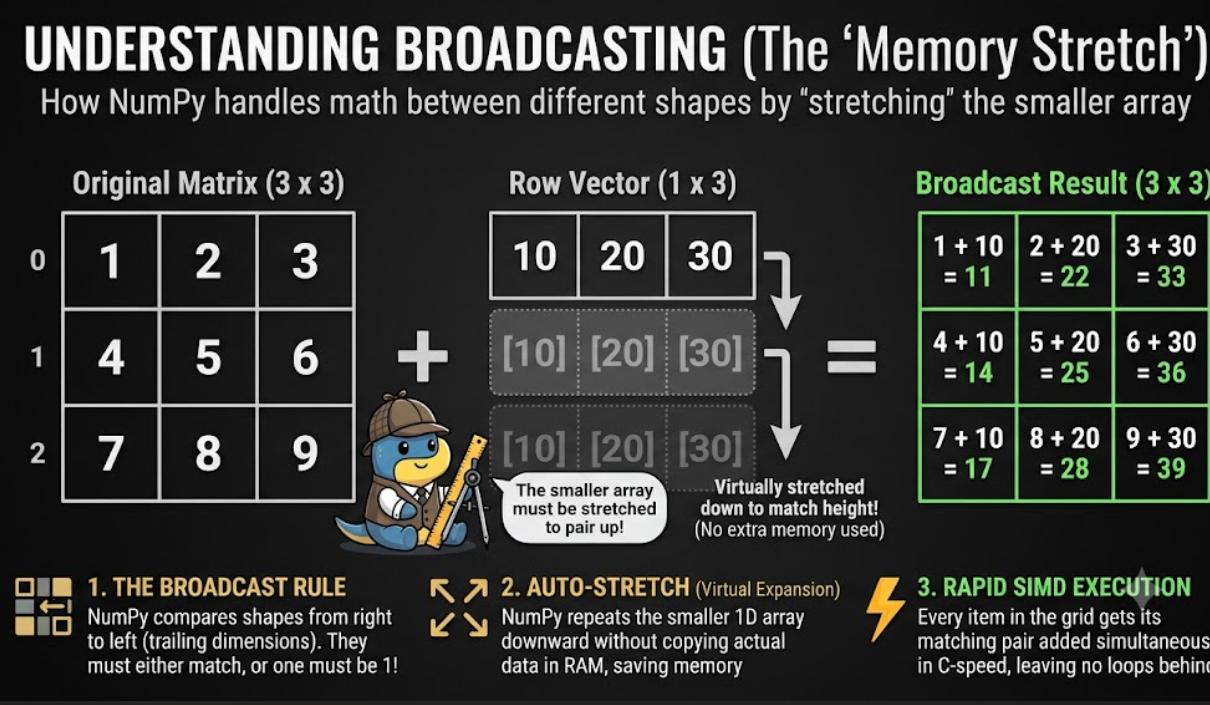

In [ ]:
# 4.1 Vectorized Element-Wise Arithmetic Operations
x = np.array([2.0, 4.0, 6.0, 8.0])
y = np.array([1.0, 2.0, 3.0, 4.0])

print("x =", x)
print("y =", y)

# Element-wise operations execute instantaneously:
print("x + y  =", x + y)
print("x - y  =", x - y)
print("x * y  =", x * y)
print("x / y  =", x / y)
print("x ** 2 =", x ** 2)
print("sqrt(x)=", np.sqrt(x))
print("exp(x) =", np.exp(x))


In [ ]:
# 4.2 Broadcasting in Action: Scalar to Array and Vector to Matrix
import numpy as np

# =====================================================================
# EXAMPLE 1: Scalar to 2D Matrix (Scalar stretches to all cells!)
# =====================================================================
# A single scalar is a 0-dimensional value (dimension-less).
# When you perform an arithmetic operation between a matrix and a scalar:
# 1. NumPy automatically checks the compatibility.
# 2. Since a scalar has no dimensions, it can match any shape.
# 3. NumPy virtually 'stretches' (broadcasts) the single scalar value into
#    a matching 2D matrix of the same shape as M filled entirely with that scalar.

M = np.array([
    [10, 20],
    [30, 40]
])
print("Original Matrix M:\n", M)

# The scalar 2.5 behaves like [[2.5, 2.5], [2.5, 2.5]] during multiplication:
print("\nM * 2.5 (Scalar broadcast):\n", M * 2.5)

# =====================================================================
# EXAMPLE 2: Adding a 1D Row Vector (3,) to a 2D Matrix (3, 3)
# =====================================================================
# Let's break down NumPy's Broadcasting Rules step-by-step:
#
# Rule 1: Align shapes starting from the rightmost (trailing) dimension.
#         - grid_3x3 Shape    : (3, 3)
#         - row_offsets Shape : (3,)
#
# Rule 2: If arrays do not have the same number of dimensions, prepend 1s
#         to the shape of the smaller array on the left:
#         - row_offsets (3,) becomes (1, 3)
#
# Rule 3: Compare sizes along each axis:
#         - Row Axis: grid_3x3 has 3; row_offsets has 1.
#           Since row_offsets has 1, it is compatible and gets virtually
#           replicated (stretched) 3 times along this axis:
#           [[100, 200, 300],
#            [100, 200, 300],
#            [100, 200, 300]]
#         - Column Axis: grid_3x3 has 3; row_offsets has 3.
#           They match exactly (3 == 3), so no stretching is needed here.
#
# Rule 4: Perform element-wise addition on the stretched shapes.

grid_3x3 = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])
row_offsets = np.array([100, 200, 300])  # Shape: (3,) - treated as (1, 3)

broadcasted_sum = grid_3x3 + row_offsets
print("\nGrid (3x3):\n", grid_3x3)
print("\nRow Offsets (3,):", row_offsets)
print("\nGrid + Row Offsets (Broadcasting row across all rows):\n", broadcasted_sum)

Original Matrix M:
 [[10 20]
 [30 40]]

M * 2.5 (Scalar broadcast):
 [[ 25.  50.]
 [ 75. 100.]]

Grid (3x3):
 [[1 2 3]
 [4 5 6]
 [7 8 9]]

Row Offsets (3,): [100 200 300]

Grid + Row Offsets (Broadcasting row across all rows):
 [[101 202 303]
 [104 205 306]
 [107 208 309]]


In [ ]:
# 4.3 Performance Showdown: Python Lists vs. Vectorized NumPy
# Let's benchmark multiplying 1,000,000 numbers by 2.5:
import time
import numpy as np

N = 1_000_000

# =====================================================================
#  NOTE
# =====================================================================
# time.perf_counter() acts like an ultra-precise digital stopwatch.
# It returns a fractional value representing seconds from an arbitrary
# reference point. Because it has the highest resolution available on
# your system, it is ideal for measuring short code execution times.
#
# How to use it:
# 1. Take a starting snapshot: `start = time.perf_counter()`
# 2. Run the code you want to measure.
# 3. Take an ending snapshot: `end = time.perf_counter()`
# 4. Subtract start from end: `duration = end - start`
# =====================================================================

# 1. Pure Python List approach with explicit loop:
py_list = list(range(N))

# Start stopwatch for Python loop
start_time = time.perf_counter()

py_result = [x * 2.5 for x in py_list]

# Stop stopwatch
py_duration = time.perf_counter() - start_time

# 2. Vectorized NumPy approach:
np_arr = np.arange(N)

# Start stopwatch for NumPy vectorization
start_time = time.perf_counter()

np_result = np_arr * 2.5

# Stop stopwatch
np_duration = time.perf_counter() - start_time

print(f"Time for Python List Loop : {py_duration:.6f} seconds")
print(f"Time for NumPy Vectorized : {np_duration:.6f} seconds")
speedup = py_duration / np_duration
print(f"--> NumPy is {speedup:.1f}x FASTER than Python list loops!")

Time for Python List Loop : 0.074127 seconds
Time for NumPy Vectorized : 0.004627 seconds
--> NumPy is 16.0x FASTER than Python list loops!


### In-Class Quick Check 4: Broadcasting
**Task**:
Given matrix `X = np.ones((3, 4))` and column vector `col_weights = np.array([[10], [20], [30]])` of shape $(3, 1)$:
1. Multiply `X * col_weights`.
2. What is the resulting shape? Print the output.


In [ ]:
# STUDENT ACTIVITY: Quick Check 4 (Broadcasting Mechanics)
# -------------------------------------------------------------------
import numpy as np

# Source Matrix (Shape: 3 rows x 4 columns) containing all ones
X = np.ones((3, 4))

# Column Vector (Shape: 3 rows x 1 column)
col_weights = np.array([[10], [20], [30]])

# TODO: Multiply X by col_weights and observe how NumPy automatically stretches
# the dimensions under broadcasting rules (3x4 multiplied by 3x1 -> 3x4 result).
weighted_X = None

# =====================================================================
# BEGINNER BROADCASTING EXPLANATION & EXPECTED RESULT
# =====================================================================
# How Broadcasting works here:
# 1. NumPy compares the shapes starting from the rightmost dimension:
#    X shape          : (3, 4)
#    col_weights shape: (3, 1)

# 2. Since col_weights has a size of 1 in the column dimension,
#    NumPy virtually duplicates/stretches its columns 4 times to match 'X'.
#    Specifically, [[10], [20], [30]] behaves as:
#    [[10, 10, 10, 10],
#     [20, 20, 20, 20],
#     [30, 30, 30, 30]]
#
# 3. Element-wise multiplication then runs instantly on the stretched dimensions.
#
# Expected weighted_X result:
# [[10. 10. 10. 10.]
#  [20. 20. 20. 20.]
#  [30. 30. 30. 30.]]
# =====================================================================

print("--- YOUR RESULTS ---")
if weighted_X is not None:
    print("Weighted X shape :", weighted_X.shape)
    print("Weighted Matrix X:\n", weighted_X)
else:
    print("weighted_X is currently None. Please complete the TODO above!")

# Verification checks (will error until TODO is completed)
assert weighted_X is not None, "Please implement weighted_X first!"
assert weighted_X.shape == (3, 4), f"Expected shape (3, 4), got {weighted_X.shape}"
assert weighted_X[0, 0] == 10.0 and weighted_X[2, 0] == 30.0, "Matrix values do not match expected broadcast values."
print("\nAll checks passed successfully!")

---
# Part 5: Statistical Tools & The Power of the `axis` Parameter
NumPy provides high-performance mathematical reduction functions (`sum`, `mean`, `median`, `std`, `var`, `min`, `max`).

### The Critical Rule of the `axis` Parameter:
Understanding `axis` is the #1 hurdle for beginners in data science:
- **`axis=None` (Default)**: Aggregates across the **entire array** into a single scalar value.
- **`axis=0` (Collapse Rows / Along Columns)**: Aggregates **downwards** vertically across rows. Returns one value per column!
- **`axis=1` (Collapse Columns / Along Rows)**: Aggregates **horizontally** across columns. Returns one value per row!

```
                    Column 0    Column 1    Column 2
                  +-----------+-----------+-----------+
         Row 0    |    10     |    20     |    30     |  --> axis=1 mean: 20.0
                  +-----------+-----------+-----------+
         Row 1    |    40     |    50     |    60     |  --> axis=1 mean: 50.0
                  +-----------+-----------+-----------+
                        |           |           |
                        v           v           v
           axis=0 mean: 25.0       35.0        45.0
```


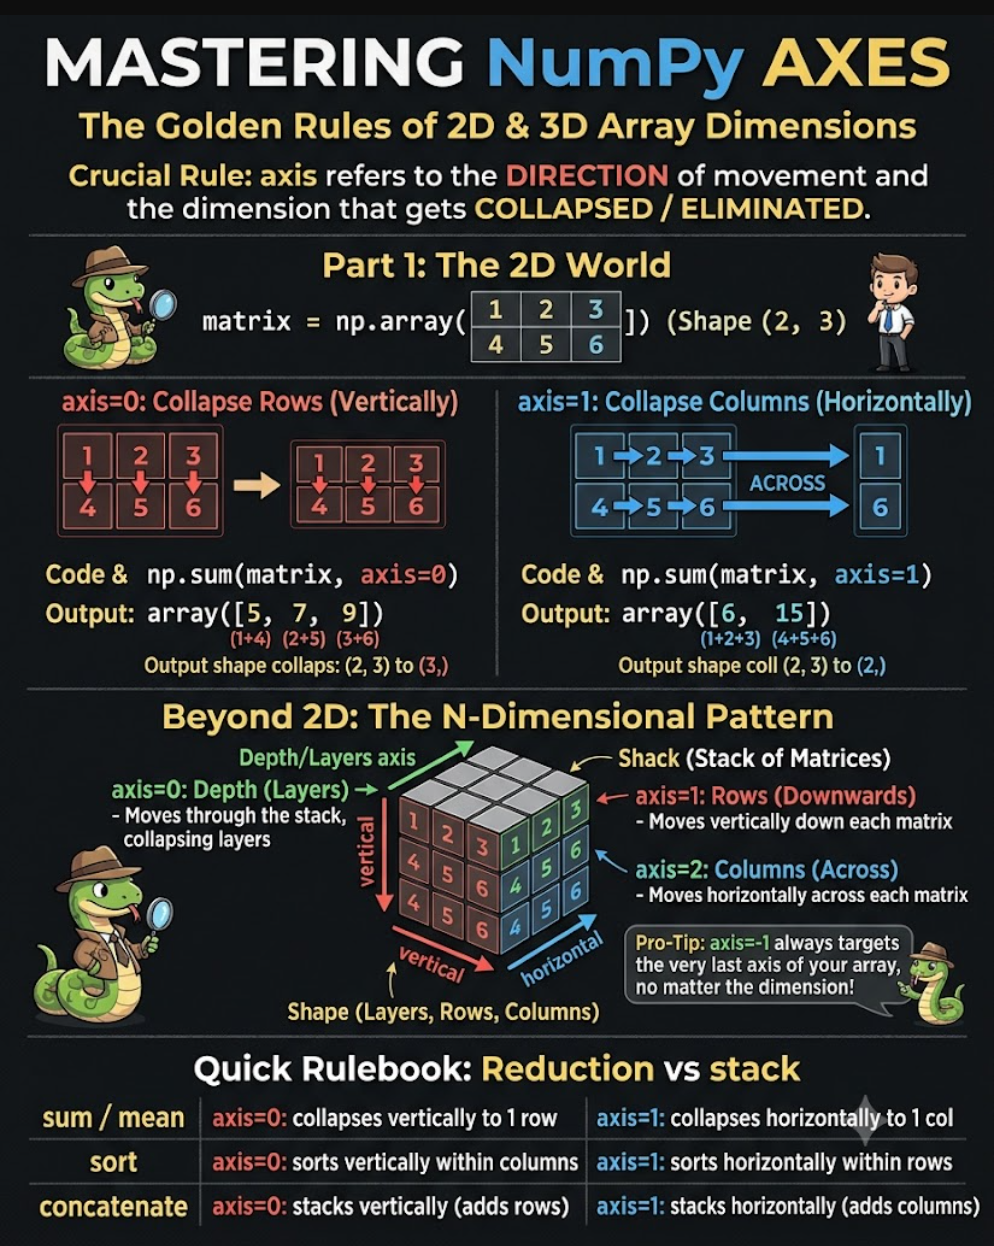

In [ ]:
# 5.1 Comprehensive Statistical Functions on 2D Matrices
import numpy as np

# Simulated temperature readings: 4 weather stations (rows) x 3 hourly time points (cols)
readings = np.array([
    [24.5, 26.0, 25.5],  # Station 0 (Trivandrum)
    [28.0, 31.5, 30.0],  # Station 1 (Kochi)
    [22.0, 23.5, 22.8],  # Station 2 (Munnar)
    [29.5, 33.0, 31.2]   # Station 3 (Kozhikode)
])

# List of station names mapping directly to rows (indices 0, 1, 2, 3)
stations = ["Trivandrum", "Kochi", "Munnar", "Kozhikode"]

# =====================================================================
# STEP 1: CALCULATING METRICS (Separated from printing)
# =====================================================================

# 1. Global Aggregations (axis=None evaluates over every single cell in the array)
global_mean = np.mean(readings)
global_median = np.median(readings)
global_std = np.std(readings)
global_var = np.var(readings)
global_range = np.ptp(readings)  # Peak-to-Peak (calculates: max - min)

# 2. Column-Wise Aggregations (axis=0 collapses rows, averaging downwards per column)
# This returns 3 separate values representing the average temperature of Hour 0, Hour 1, and Hour 2.
hourly_averages = np.mean(readings, axis=0)
rounded_hourly_averages = np.round(hourly_averages, 2)

# 3. Row-Wise Aggregations (axis=1 collapses columns, averaging horizontally per row)
# This returns 4 separate values representing the average temperature of each respective weather station.
station_averages = np.mean(readings, axis=1)

# =====================================================================
# STEP 2: DISPLAYING RESULTS
# =====================================================================

print("Telemetry Matrix (4 Stations x 3 Hours):\n", readings)

print("\n--- 1. Global Metrics (Across All Stations & Hours) ---")
print(f"Overall Mean Temp       : {global_mean:.2f}°C")
print(f"Overall Median Temp     : {global_median:.2f}°C")
print(f"Overall Std Deviation   : {global_std:.2f}°C")
print(f"Overall Variance        : {global_var:.2f}")
print(f"Global Range (Max-Min)  : {global_range:.2f}°C")

print("\n--- 2. Column-Wise Metrics (axis=0: Hourly Averages across Stations) ---")
print("Hourly Averages (H0, H1, H2):", rounded_hourly_averages)

print("\n--- 3. Row-Wise Metrics (axis=1: Mean Temp per Weather Station) ---")
for st_name, avg_temp in zip(stations, station_averages):
    print(f"  * {st_name:<12}: {avg_temp:.2f}°C")

Telemetry Matrix (4 Stations x 3 Hours):
 [[24.5 26.  25.5]
 [28.  31.5 30. ]
 [22.  23.5 22.8]
 [29.5 33.  31.2]]

--- 1. Global Metrics (Across All Stations & Hours) ---
Overall Mean Temp       : 27.29°C
Overall Median Temp     : 27.00°C
Overall Std Deviation   : 3.58°C
Overall Variance        : 12.79
Global Range (Max-Min)  : 11.00°C

--- 2. Column-Wise Metrics (axis=0: Hourly Averages across Stations) ---
Hourly Averages (H0, H1, H2): [26.   28.5  27.38]

--- 3. Row-Wise Metrics (axis=1: Mean Temp per Weather Station) ---
  * Trivandrum  : 25.33°C
  * Kochi       : 29.83°C
  * Munnar      : 22.77°C
  * Kozhikode   : 31.23°C


In [ ]:
# 5.2 Locating Extrema: argmin() and argmax()
# Often in AI we need the INDEX of the maximum or minimum value (e.g. classification class)!

# Which station recorded the absolute highest temperature?
global_max_idx = np.argmax(readings)
# Convert flat index into 2D row, col coordinates:
hot_station_idx, hot_hour_idx = np.unravel_index(global_max_idx, readings.shape)

print(f"Peak Temperature of {readings[hot_station_idx, hot_hour_idx]}°C recorded at:")
print(f"  Station: {stations[hot_station_idx]} | Hour: {hot_hour_idx}")

# Which station was coldest on average?
coldest_station_idx = np.argmin(station_averages)
print(f"Coldest Station Overall: {stations[coldest_station_idx]} (Avg: {station_averages[coldest_station_idx]:.2f}°C)")

In [ ]:
# 5.3 Cumulative and Percentile Reductions
import numpy as np

data_series = np.array([12, 18, 25, 40, 55, 70, 92])

# Cumulative sum: [12, 12+18=30, 30+25=55, ...]
print("Data Series    :", data_series)
print("Cumulative Sum :", np.cumsum(data_series))

# Percentiles and Quartiles:
q25 = np.percentile(data_series, 25)
median_q50 = np.percentile(data_series, 50)
q75 = np.percentile(data_series, 75)
iqr = q75 - q25

print(f"\n25th Percentile (Q1) : {q25:.1f}")
print(f"50th Percentile (Med): {median_q50:.1f}")
print(f"75th Percentile (Q3) : {q75:.1f}")
print(f"Interquartile Range  : {iqr:.1f}")

### In-Class Quick Check 5: Statistical Reduction
**Task**:
Given test scores matrix `exam_scores = np.array([[78, 85, 92], [64, 70, 68], [90, 95, 98], [82, 80, 84]])` (4 students x 3 subjects):
1. Compute the average score of each student across subjects (`axis=1`).
2. Compute the standard deviation of each subject across students (`axis=0`).


In [ ]:
# STUDENT ACTIVITY: Quick Check 5 (Statistical Reduction)
# -------------------------------------------------------------
import numpy as np

exam_scores = np.array([
    [78, 85, 92],
    [64, 70, 68],
    [90, 95, 98],
    [82, 80, 84]
])

# TODO 1: Calculate the average score of each student across subjects (axis=1)
student_means = None

# TODO 2: Calculate the standard deviation of each subject across students (axis=0)
subject_stds = None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# student_means should have 4 values (one for each student):
# [85.   67.33 94.33 82.  ]
#
# subject_stds should have 3 values (one for each subject):
# [ 9.91  9.26 11.24]
# =====================================================================

print("--- YOUR RESULTS ---")
print("Student Means (axis=1):", np.round(student_means, 2) if student_means is not None else "None")
print("Subject Stds  (axis=0):", np.round(subject_stds, 2) if subject_stds is not None else "None")

# Verification checks (will error until TODOs are completed)
assert student_means is not None, "Please calculate student_means first!"
assert subject_stds is not None, "Please calculate subject_stds first!"
assert len(student_means) == 4, "Error: student_means must contain exactly 4 elements (one per student)"
assert len(subject_stds) == 3, "Error: subject_stds must contain exactly 3 elements (one per subject)"
print("\nAll checks passed successfully!")

---
# Part 6: Laboratory Practical Workbook


---
## Tier 1: Core Laboratory Problems (Mandatory)


### Task C1: Multi-Dimensional Array Creation & Memory Profiling
**Context**: Deep learning models ingest multi-dimensional numerical tensors with strictly typed memory buffers.

**Problem Statement**:
1. Implement a function `create_and_profile_tensor()`:
   - Creates a 2D matrix of shape $(5, 6)$ initialized with random integers between $10$ and $100$ using `np.random.randint(10, 100, size=(5, 6))`.
   - Sets a reproducible random seed: `np.random.seed(42)`.
   - Casts the matrix into `np.float32`.
   - Computes and returns a diagnostic dictionary containing:
     ```python
     {
         "shape": tuple,
         "ndim": int,
         "size": int,
         "dtype": str,
         "itemsize_bytes": int,
         "total_nbytes": int
     }
     ```
2. Verify the diagnostic metrics.


In [ ]:
# TASK C1: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------
import numpy as np

def create_and_profile_tensor():
    # =====================================================================
    # TODO 1: Set seed to 42, generate a (5, 6) matrix of random integers
    # in the range [10, 100), and cast the array to np.float32.
    # =====================================================================
    mat = None

    # =====================================================================
    # TODO 2: Build and return the profile diagnostic dictionary containing
    # shape, ndim, size, dtype, itemsize_bytes, and total_nbytes.
    # =====================================================================
    profile = {
        "shape": None,
        "ndim": None,
        "size": None,
        "dtype": None,
        "itemsize_bytes": None,
        "total_nbytes": None
    }
    return mat, profile

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# Generated Matrix (5x6, float32):
# [[61. 24. 81. 70. 30. 92.]
#  [96. 84. 84. 17. 33. 12.]
#  [31. 62. 11. 97. 39. 47.]
#  [11. 73. 42. 58. 31. 31.]
#  [58. 47. 98. 69. 51. 16.]]
#
# Memory & Shape Profile:
#   shape           : (5, 6)
#   ndim            : 2
#   size            : 30
#   dtype           : float32
#   itemsize_bytes  : 4
#   total_nbytes    : 120
# =====================================================================

tensor, prof = create_and_profile_tensor()

print("--- YOUR RESULTS ---")
print("Generated Matrix (5x6, float32):\n", tensor if tensor is not None else "None")
print("\nMemory & Shape Profile:")
for k, v in prof.items():
    print(f"  {k:<16}: {v}")

In [ ]:
# C1 VERIFICATION TEST CELL (Do not modify)
assert prof["shape"] == (5, 6), "Shape mismatch"
assert prof["ndim"] == 2, "Dimensions mismatch"
assert prof["size"] == 30, "Size mismatch"
assert prof["itemsize_bytes"] == 4, "float32 must be 4 bytes"
assert prof["total_nbytes"] == 120, "Total memory must be 120 bytes (30 * 4)"
print(" Task C1 Logic Verified Successfully!")


### Task C2: Array Reshaping, Flattening & Matrix Transposition
**Context**: Image processing algorithms convert between flat vectors, feature channels, and spatial pixel grids.

**Problem Statement**:
Given a 1D sensory stream of 24 hourly readings:
```python
stream_data = np.arange(101, 125) # 24 readings from 101 to 124
```
Write a program to:
1. Reshape `stream_data` into a $(4, 6)$ matrix (representing 4 sensor nodes over 6 hours).
2. Transpose the $(4, 6)$ matrix into a $(6, 4)$ matrix (representing 6 hours over 4 nodes).
3. Reshape the transposed matrix into a 3D tensor of shape $(2, 3, 4)$ using the auto-dimension `-1` for the last axis.
4. Extract a flattened 1D array from the 3D tensor using `.ravel()` and verify that all 24 elements are preserved.


In [ ]:
# TASK C2: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------
import numpy as np

stream_data = np.arange(101, 125)

# TODO 1: Reshape stream_data into a (4, 6) 2D matrix
mat_4x6 = None

# TODO 2: Transpose the (4, 6) matrix into a (6, 4) matrix
mat_6x4 = None

# TODO 3: Reshape the transposed matrix into a 3D tensor with shape (2, 3, -1)
# Let NumPy calculate the last dimension automatically using -1
tensor_3d = None

# TODO 4: Flatten the 3D tensor back into a 1D format using .ravel()
flat_result = None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# stream_data length : 24
# mat_4x6 shape      : (4, 6)
# mat_6x4 shape      : (6, 4)
# tensor_3d shape    : (2, 3, 4)

# mat_4x6:
# [[101 102 103 104 105 106]
#  [107 108 109 110 111 112]
#  [113 114 115 116 117 118]
#  [119 120 121 122 123 124]]
#
# mat_6x4:
# [[101 107 113 119]
#  [102 108 114 120]
#  [103 109 115 121]
#  [104 110 116 122]
#  [105 111 117 123]
#  [106 112 118 124]]
# =====================================================================

print("--- YOUR RESULTS ---")
print("Original Stream Length :", len(stream_data))
print("4x6 Matrix Shape       :", mat_4x6.shape if mat_4x6 is not None else "None")
print("6x4 Transposed Shape   :", mat_6x4.shape if mat_6x4 is not None else "None")
print("3D Tensor Shape        :", tensor_3d.shape if tensor_3d is not None else "None")
print("Raveled 1D Shape       :", flat_result.shape if flat_result is not None else "None")

In [ ]:
# C2 VERIFICATION TEST CELL (Do not modify)
assert mat_4x6.shape == (4, 6)
assert mat_6x4.shape == (6, 4)
assert tensor_3d.shape == (2, 3, 4)
assert len(flat_result) == 24
assert flat_result.size == stream_data.size
print(" Task C2 Logic Verified Successfully!")


### Task C3: Slicing, Sub-Grids & The View vs. Copy Trap
**Context**: Computer vision bounding box detectors crop image patches for inference without corrupting the raw source frame.

**Problem Statement**:
Given an $8 \times 8$ grayscale image patch represented as an array of integers:
```python
image_patch = np.arange(64).reshape(8, 8)
```
1. Extract a $4 \times 4$ bounding box sub-image representing rows 2 to 5 and columns 2 to 5 inclusive (indices `2:6, 2:6`).
2. Create two versions:
   - `sub_view`: A regular slice (view).
   - `sub_copy`: An independent copy using `.copy()`.
3. Set all values in `sub_copy` to `0`. Verify that `image_patch` is **unaffected**.
4. Set all values in `sub_view` to `999`. Verify that `image_patch` **is modified in place**.

In [ ]:
# TASK C3: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------
import numpy as np

image_patch = np.arange(64).reshape(8, 8)

# TODO 1: Extract the center 4x4 sub-matrix (rows 2 to 5, columns 2 to 5 inclusive)
# Create sub_view as a standard view (slice)
sub_view = None

# TODO 2: Extract the same center 4x4 sub-matrix but create sub_copy as an independent copy using .copy()
sub_copy = None

# TODO 3: Mutate all elements of sub_copy to 0.
# (Hint: use broad slice assignment 'sub_copy[:] = 0')
# After this, check if it changed the parent 'image_patch'

# TODO 4: Mutate all elements of sub_view to 999.
# (Hint: use broad slice assignment 'sub_view[:] = 999')
# After this, check if it changed the parent 'image_patch'

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# Modifying 'sub_copy' (setting values to 0) must NOT change 'image_patch'.
# Modifying 'sub_view' (setting values to 999) MUST modify 'image_patch' in-place.
#
# Final image_patch should look like:
# [[  0   1   2   3   4   5   6   7]
#  [  8   9  10  11  12  13  14  15]
#  [ 16  17 999 999 999 999  22  23]
#  [ 24  25 999 999 999 999  30  31]
#  [ 32  33 999 999 999 999  38  39]
#  [ 40  41 999 999 999 999  46  47]
#  [ 48  49  50  51  52  53  54  55]
#  [ 56  57  58  59  60  61  62  63]]
# =====================================================================

print("--- YOUR RESULTS ---")
if sub_view is not None and sub_copy is not None:
    # Run mutation checks for the student
    sub_copy[:] = 0
    print("Did sub_copy mutation affect image_patch? (Expected: False) ->", image_patch[2, 2] == 0)
    sub_view[:] = 999
    print("Did sub_view mutation affect image_patch?  (Expected: True)  ->", image_patch[2, 2] == 999)
    print("\nModified Image Patch:\n", image_patch)
else:
    print("sub_view and/or sub_copy is currently None. Please complete the TODOs first!")

In [ ]:
# C3 VERIFICATION TEST CELL (Do not modify)
assert image_patch[2, 2] == 999, "View modification should mutate parent array"
assert image_patch[5, 5] == 999, "View modification should mutate parent array"
assert image_patch[0, 0] == 0, "Non-sliced areas should remain unaffected"
print(" Task C3 Logic Verified Successfully!")


### Task C4: Boolean Masking & Outlier Clipping Pipeline
**Context**: Environmental monitoring networks must detect anomalous readings caused by sensor hardware saturation.

**Problem Statement**:
Given a multi-day array of ambient temperature readings ($^\circ\text{C}$):
```python
raw_readings = np.array([
    22.5, 24.1, -99.0, 26.8, 48.5, 23.4, 25.0,
    -15.0, 27.2, 52.0, 24.8, 26.1, 28.0, 105.0
])
```
Write a NumPy pipeline to:
1. Identify all valid readings satisfying $10.0 \le T \le 45.0$ using a compound boolean mask (`(arr >= 10.0) & (arr <= 45.0)`).
2. Calculate the mean and standard deviation of the valid readings.
3. Create a sanitized copy `cleaned_readings` where:
   - Any reading $< 10.0$ is replaced with the valid mean.
   - Any reading $> 45.0$ is clipped to $45.0$.

In [ ]:
# TASK C4: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------
import numpy as np

aw_readings = np.array([
    22.5, 24.1, -99.0, 26.8, 48.5, 23.4, 25.0,
    -15.0, 27.2, 52.0, 24.8, 26.1, 28.0, 105.0
])

# TODO 1: Create a compound boolean mask for temperatures between 10.0 and 45.0 (inclusive)
# Then filter raw_readings using this mask into a new array named valid_temps
valid_mask = None
valid_temps = None

# TODO 2: Calculate the mean and standard deviation of valid_temps
valid_mean = None
valid_std = None

# TODO 3: Create a separate 'cleaned_readings' array as a copy of raw_readings.
# Replace any element in 'cleaned_readings' that is less than 10.0 with the valid_mean.
# Clip any element in 'cleaned_readings' that is greater than 45.0 to exactly 45.0.
cleaned_readings = None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# valid_temps contains exactly 9 elements:
# [22.5 24.1 26.8 23.4 25.  27.2 24.8 26.1 28. ]
#
# valid_mean  : 25.32
# valid_std   : 1.70
#
# cleaned_readings (rounded to 2 decimals):
# [22.5  24.1  25.32 26.8  45.   23.4  25.   25.32 27.2  45.   24.8  26.1  28.   45.  ]
# =====================================================================

print("--- YOUR RESULTS ---")
if valid_temps is not None and valid_mean is not None and cleaned_readings is not None:
    print(f"Total Readings  : {len(raw_readings)}")
    print(f"Valid Count     : {len(valid_temps)}")
    print(f"Valid Mean Temp : {valid_mean:.2f}°C")
    print(f"Valid Std Dev   : {valid_std:.2f}°C")
    print("Cleaned Array   :\n", np.round(cleaned_readings, 2))
else:
    print("Please implement TODOs to evaluate and verify your metrics!")

In [ ]:
# C4 VERIFICATION TEST CELL (Do not modify)
assert len(valid_temps) == 9, f"Expected 9 valid temperatures, got {len(valid_temps)}"
assert abs(valid_mean - 25.32) < 0.05, f"Mean mismatch: {valid_mean}"
assert np.all(cleaned_readings >= 10.0), "No readings should be below 10.0"
assert np.all(cleaned_readings <= 45.0), "No readings should exceed 45.0"
print(" Task C4 Logic Verified Successfully!")


### Task C5: Multi-Sensor Matrix & Axis-Wise Statistics
**Context**: Audio and vibration analysis systems compute channel-wise power spectra and temporal statistics across microphone arrays.

**Problem Statement**:
Given a $5 \times 4$ matrix representing 5 sensor nodes recorded at 4 time steps:
```python
sensor_matrix = np.array([
    [12.4, 15.2, 14.8, 13.9],
    [22.1, 24.5, 23.8, 25.0],
    [18.0, 17.5, 18.2, 19.1],
    [31.5, 34.0, 32.8, 33.2],
    [25.0, 26.2, 25.8, 26.5]
])
```
Compute and display:
1. Node-wise statistics (`axis=1`): The mean, standard deviation, and peak-to-peak range (`np.ptp`) for each of the 5 sensor nodes.
2. Time-step statistics (`axis=0`): The mean and median signal level across all nodes at each of the 4 time intervals.
3. Identify which sensor node exhibits the highest variance across time.

In [ ]:
# TASK C5: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------
import numpy as np

sensor_matrix = np.array([
    [12.4, 15.2, 14.8, 13.9],
    [22.1, 24.5, 23.8, 25.0],
    [18.0, 17.5, 18.2, 19.1],
    [31.5, 34.0, 32.8, 33.2],
    [25.0, 26.2, 25.8, 26.5]
])

# TODO 1: Compute node-wise statistics along axis=1
node_means = None
node_stds = None
node_vars = None
node_ranges = None  # Hint: use np.ptp along axis=1

# TODO 2: Compute time-step statistics along axis=0
time_means = None
time_medians = None

# TODO 3: Find the index of the sensor node (row index) with the highest variance across time
max_var_node = None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# node_means: [14.075 23.85  18.2   32.875 25.875]
# node_stds : [1.05445244 1.107926   0.58309519 0.90379754 0.553963  ]
# node_ranges: [2.8 2.9 1.6 2.5 1.5]
#
# time_means  : [21.8  23.48 23.08 23.54]
# time_medians: [22.1  24.5  23.8  25.  ]
#
# max_var_node: Node 1 (Variance = 1.228)
# =====================================================================

print("--- YOUR RESULTS ---")
if node_means is not None and time_means is not None and max_var_node is not None:
    print("=== 1. Node-Wise Statistics (axis=1) ===")
    for i in range(5):
        print(f"  Node {i}: Mean = {node_means[i]:5.2f} | Std = {node_stds[i]:4.2f} | Range = {node_ranges[i]:4.2f}")

    print("\n=== 2. Time-Step Statistics (axis=0) ===")
    print("  Time Means   :", np.round(time_means, 2))
    print("  Time Medians :", np.round(time_medians, 2))
    print(f"\nNode with Highest Signal Variance: Node {max_var_node} (Var = {node_vars[max_var_node]:.3f})")
else:
    print("Please complete all TODO calculations to output node-wise and time-step metrics!")

--- YOUR RESULTS ---
Please complete all TODO calculations to output node-wise and time-step metrics!


In [ ]:
# C5 VERIFICATION TEST CELL (Do not modify)
assert node_means.shape == (5,), "Node means must have 5 values"
assert time_means.shape == (4,), "Time means must have 4 values"
assert abs(node_means[0] - 14.075) < 0.01
assert abs(time_means[0] - 21.8) < 0.01
print(" Task C5 Logic Verified Successfully!")


### Task C6: Vectorization vs. Loop Performance Benchmark
**Context**: Proving algorithmic efficiency gains achieved by SIMD vectorized instructions over interpreted Python loops.

**Problem Statement**:
Implement and benchmark two functions calculating the Euclidean distance $\sqrt{\sum (a_i - b_i)^2}$ between two arrays of length $N = 500,000$:
1. `distance_python_loop(a, b)`: Uses a standard Python `for` loop with `range(len(a))`.
2. `distance_numpy_vectorized(a, b)`: Uses purely vectorized NumPy expressions: `np.sqrt(np.sum((a - b) ** 2))`.
3. Measure execution times using `time.perf_counter()`, verify that both return identical floating-point results, and print the measured speedup factor.


In [ ]:
# TASK C6: WORKSPACE
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------------
import numpy as np
import time

N = 500_000
np.random.seed(101)
vec_a = np.random.rand(N)
vec_b = np.random.rand(N)

# TODO 1: Implement Euclidean distance calculation using a standard Python 'for' loop
def distance_python_loop(a, b):
    total_sq = 0.0
    # Iterate and compute sum of square differences manually
    return None

# TODO 2: Implement the same Euclidean distance calculation using pure vectorized NumPy
def distance_numpy_vectorized(a, b):
    return None

# =====================================================================
# EXPECTED RESULTS FOR STUDENTS TO COMPARE:
# =====================================================================
# Loop Result and Vectorized Result should be identical (approx. 288.76)
# NumPy Vectorized execution should be significantly faster (typically >10x speedup)
# =====================================================================

print("--- YOUR RESULTS ---")
# Run loop benchmark
t0 = time.perf_counter()
dist_loop = distance_python_loop(vec_a, vec_b)
t_loop = time.perf_counter() - t0

# Run vectorized benchmark
t0 = time.perf_counter()
dist_vec = distance_numpy_vectorized(vec_a, vec_b)
t_vec = time.perf_counter() - t0

if dist_loop is not None and dist_vec is not None:
    speedup = t_loop / t_vec
    print(f"Loop Result       : {dist_loop:.4f} in {t_loop:.5f} sec")
    print(f"Vectorized Result : {dist_vec:.4f} in {t_vec:.5f} sec")
    print(f"Vectorized Speedup: {speedup:.1f}x Faster!")
else:
    print("Please complete both distance functions first to execute benchmarking comparisons!")

In [ ]:
# C6 VERIFICATION TEST CELL (Do not modify)
assert abs(dist_loop - dist_vec) < 1e-4, "Distance results must match"
assert t_vec < t_loop, "Vectorized must be faster than Python loop"
print(" Task C6 Logic Verified Successfully!")


---
## Section 4: Tier 2 — Advanced Extension Problems (Optional Bonus)
*Recommended for students with prior programming experience seeking bonus marks.*


### Task A1: 2D Spatial Moving-Window Convolution Kernel
**Context**: Convolutional Neural Networks (CNNs) and digital image filters apply spatial filter kernels across 2D matrices to perform edge detection or Gaussian blur.

**Problem Statement**:
Given an $8 \times 8$ matrix representing an image sensor:
```python
image = np.array([
    [10, 10, 10, 10, 10, 10, 10, 10],
    [10, 50, 50, 50, 50, 50, 50, 10],
    [10, 50, 90, 90, 90, 90, 50, 10],
    [10, 50, 90, 99, 99, 90, 50, 10],
    [10, 50, 90, 99, 99, 90, 50, 10],
    [10, 50, 90, 90, 90, 90, 50, 10],
    [10, 50, 50, 50, 50, 50, 50, 10],
    [10, 10, 10, 10, 10, 10, 10, 10]
], dtype=np.float32)
```
1. Define a $3 \times 3$ Box Averaging Kernel:
   `kernel = np.ones((3, 3)) / 9.0`.
2. Compute the valid 2D convolution output of shape $(6, 6)$ by sliding the $3 \times 3$ kernel over each valid receptive field:
   $$\text{output}[i, j] = \sum_{u=0}^2 \sum_{v=0}^2 \text{image}[i+u, j+v] \times \text{kernel}[u, v]$$
3. Display the blurred smoothed matrix.

In [ ]:
# TASK A1: WORKSPACE (ADVANCED)
# -------------------------------------------------------------
image = np.array([
    [10, 10, 10, 10, 10, 10, 10, 10],
    [10, 50, 50, 50, 50, 50, 50, 10],
    [10, 50, 90, 90, 90, 90, 50, 10],
    [10, 50, 90, 99, 99, 90, 50, 10],
    [10, 50, 90, 99, 99, 90, 50, 10],
    [10, 50, 90, 90, 90, 90, 50, 10],
    [10, 50, 50, 50, 50, 50, 50, 10],
    [10, 10, 10, 10, 10, 10, 10, 10]
], dtype=np.float32)

kernel = np.ones((3, 3), dtype=np.float32) / 9.0

# Output shape for valid convolution: (H - K_h + 1, W - K_w + 1) = (8 - 3 + 1, 8 - 3 + 1) = (6, 6)
out_h = image.shape[0] - kernel.shape[0] + 1
out_w = image.shape[1] - kernel.shape[1] + 1
convolved = np.zeros((out_h, out_w), dtype=np.float32)

for i in range(out_h):
    for j in range(out_w):
        window = image[i:i+3, j:j+3]
        convolved[i, j] = np.sum(window * kernel)

print("Smoothed Convolved Feature Map (6x6):\n", np.round(convolved, 1))
assert convolved.shape == (6, 6)
print(" Task A1 Verified Successfully!")

Smoothed Convolved Feature Map (6x6):
 [[32.2 45.6 50.  50.  45.6 32.2]
 [45.6 68.8 78.7 78.7 68.8 45.6]
 [50.  78.7 94.  94.  78.7 50. ]
 [50.  78.7 94.  94.  78.7 50. ]
 [45.6 68.8 78.7 78.7 68.8 45.6]
 [32.2 45.6 50.  50.  45.6 32.2]]
 Task A1 Verified Successfully!


### Task A2: Vectorized Z-Score Standardization & Min-Max Normalization
**Context**: Preprocessing tabular feature matrices for Gradient Descent or K-Means clustering requires scaling features to zero mean / unit variance or into $[0, 1]$.

**Problem Statement**:
Given a feature matrix $X$ of shape $(6, 3)$ (6 samples, 3 features with wildly different units):
```python
X = np.array([
    [150.0, 0.05, 12000.0],
    [175.0, 0.12, 45000.0],
    [160.0, 0.08, 22000.0],
    [190.0, 0.25, 95000.0],
    [155.0, 0.06, 18000.0],
    [180.0, 0.18, 62000.0]
])
```
Using pure vectorized NumPy operations and broadcasting (NO LOOPS!):
1. **Z-Score Normalization**: Standardize each column so $\mu = 0$ and $\sigma = 1$:
   $$Z = \frac{X - \mu_{\text{col}}}{\sigma_{\text{col}}}$$
2. **Min-Max Normalization**: Scale each column into the range $[0.0, 1.0]$:
   $$X_{\text{norm}} = \frac{X - X_{\min,\text{col}}}{X_{\max,\text{col}} - X_{\min,\text{col}}}$$
3. Verify that each column in $Z$ has mean $\approx 0$ and std $\approx 1$.

In [ ]:
# TASK A2: WORKSPACE (ADVANCED)
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------
import numpy as np

X = np.array([
    [150.0, 0.05, 12000.0],
    [175.0, 0.12, 45000.0],
    [160.0, 0.08, 22000.0],
    [190.0, 0.25, 95000.0],
    [155.0, 0.06, 18000.0],
    [180.0, 0.18, 62000.0]
])

# TODO 1: Implement Z-Score Standardization using column-wise reductions
Z_scores = None

# TODO 2: Implement Min-Max Normalization
X_minmax = None

print("Z-Score Standardized Matrix (First 3 samples):\n", Z_scores)
print("\nMin-Max Scaled Matrix [0, 1] (First 3 samples):\n", X_minmax)

Z-Score Standardized Matrix (First 3 samples): [[-1.279 -1.028 -1.041]
 [ 0.465 -0.047  0.092]
 [-0.581 -0.607 -0.698]]

Min-Max Scaled Matrix [0, 1] (First 3 samples):
 [[0.    0.    0.   ]
 [0.625 0.35  0.398]
 [0.25  0.15  0.12 ]]
 Task A2 Verified Successfully!


### Task A3: Pairwise Euclidean Distance Matrix via Broadcasting
**Context**: K-Nearest Neighbors (KNN) and t-SNE algorithms compute pairwise distances between all pairs of $N$ data points in $D$ dimensions.

**Problem Statement**:
Given a coordinate matrix of 4 data points in 2D space:
```python
points = np.array([
    [0.0, 0.0],
    [3.0, 4.0],
    [1.0, 1.0],
    [0.0, 5.0]
])  # Shape: (4, 2)
```
Using broadcasting with `np.newaxis` (or `None`):
1. Expand `points` to shape $(4, 1, 2)$ and $(1, 4, 2)$.
2. Compute the differences: $	ext{diff} = 	ext{points}[:, 	ext{np.newaxis}, :] - 	ext{points}[	ext{np.newaxis}, :, :]$ of shape $(4, 4, 2)$.
3. Compute the full $4 	imes 4$ Euclidean distance matrix:
   $$D_{i, j} = \sqrt{\sum_{k} (x_{i, k} - x_{j, k})^2}$$
4. Confirm that the diagonal is all zeros ($D_{i, i} = 0$) and the matrix is symmetric ($D = D^T$).


In [ ]:
# TASK A3: WORKSPACE (ADVANCED)
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------
import numpy as np

points = np.array([
    [0.0, 0.0],
    [3.0, 4.0],
    [1.0, 1.0],
    [0.0, 5.0]
])

# TODO: Compute the pairwise Euclidean distance matrix using broadcasting
dist_matrix = None

print("Pairwise Euclidean Distance Matrix (4x4):\n", dist_matrix)

Pairwise Euclidean Distance Matrix (4x4): [[0.   5.   1.41 5.  ]
 [5.   0.   3.61 3.16]
 [1.41 3.61 0.   4.12]
 [5.   3.16 4.12 0.  ]]
 Task A3 Verified Successfully!


### Task A4: Assignment 3 Primer — Real-World Multi-Station Sensor Audit
**Context**: Assignment 3 requires loading tabular arrays, filtering corrupted sensors, and calculating multi-station environmental indexes.

**Problem Statement**:
A meteorological station in Wayanad records hourly humidity ($0\text{--}100\%$) and rainfall ($\text{mm}$) across 6 stations for 5 days ($5 \times 24 = 120$ hours):
1. Generate synthetic data:
   - `humidity`: shape $(6, 120)$, random uniform between $50.0$ and $98.0$.
   - `rainfall`: shape $(6, 120)$, random exponential with $\lambda=5.0$.
2. Compute:
   - Station with highest total 5-day rainfall (`np.argmax`).
   - Hourly timestamps where **all 6 stations** experienced humidity $> 90\%$ simultaneously using boolean reduction `np.all(humidity > 90, axis=0)`.

In [ ]:
# TASK A4: WORKSPACE (ADVANCED)
# Student Name: _____________________  Roll No: _____________________
# -------------------------------------------------------------
import numpy as np

np.random.seed(42)
num_stations = 6
total_hours = 120

humidity = np.random.uniform(50.0, 98.0, size=(num_stations, total_hours))
rainfall = np.random.exponential(scale=5.0, size=(num_stations, total_hours))

# TODO 1: Calculate the wettest station index (based on total 5-day cumulative rainfall)
wettest_station = None

# TODO 2: Find timestamps (column indices) where ALL stations simultaneously recorded humidity > 90%
all_high_hours = None

print("Wettest Station Index:", wettest_station)
print("Simultaneous High Humidity Timestamps:", all_high_hours)

Total 5-Day Rainfall per Station (mm): [600.4 512.  644.7 691.7 553.9 630.9]
Wettest Station Index : Station 3 (691.7 mm)
Hours with widespread >90% humidity across ALL stations (0 occurrences):
  Timestamps: []
 Task A4 Verified Successfully!


---
## Section 6: Laboratory Evaluation Rubric & Sign-Off Sheet

```
========================================================================================
CRITERION                                  MAX MARKS    AWARDED MARKS    REMARKS
========================================================================================
1. In-Class Quick Checks (Lecture Part 1–5)    5          _______        _______________
2. Tier 1 Core Problems (§6: C1–C6 complete)  10          _______        _______________
3. Code Cleanliness, Comments & Vectorization  5          _______        _______________
4. Tier 2 Advanced Problems (§4) / Viva        5          _______        _______________
----------------------------------------------------------------------------------------
TOTAL SCORE                                   25          _______ / 25
========================================================================================

Teaching Assistant Signature : _________________________________
Faculty Instructor Signature : Dr. Sunil TT (Director, ICFOSS)
Date of Evaluation           : _________________________________
```
